# Heart and brain together: analysing EEG and ECG with BrainAccess

Your heartbeat leaves a mark on EEG, and heart and brain signals together can tell an adaptive system a lot about the user. In this notebook you work with a **BrainAccess MINI** recording (EEG from Fp1, Fp2, O1, O2, plus a 3-axis accelerometer). Heartbeat times (`R_peak` annotations) come from an ECG recorded at the same time with a **BrainAccess ExG** device and merged into the file. The EEG is provided already band-pass filtered 1–40 Hz. You compute heart rate and heart-rate variability, then look at **EEG locked to the heartbeat**.

In [ ]:
%matplotlib inline

import matplotlib.pyplot as plt
import mne
import numpy as np

mne.set_log_level('WARNING')

raw = mne.io.read_raw_fif('mini_heartbeat_raw.fif', preload=True)
sfreq = raw.info['sfreq']
print(raw.ch_names, f'{sfreq:g} Hz', f'{raw.times[-1]:.0f} s')
beats = np.array([a['onset'] for a in raw.annotations if a['description'] == 'R_peak'])
print(f'{len(beats)} heartbeats (R_peak annotations)')

['Fp1', 'Fp2', 'O1', 'O2', 'Accel_x', 'Accel_y', 'Accel_z'] 250 Hz 359 s
460 heartbeats (R_peak annotations)


## Heart rate and heart-rate variability

The time between successive beats is the **RR interval**. From it: instantaneous heart rate (60 / RR), the mean heart rate, **SDNN** (standard deviation of the RR intervals) and **RMSSD** (root mean square of successive differences, a common short-term variability measure).

RR: 512-1256 ms, mean 779 ms
Mean heart rate 77 bpm   SDNN 52 ms   RMSSD 37 ms


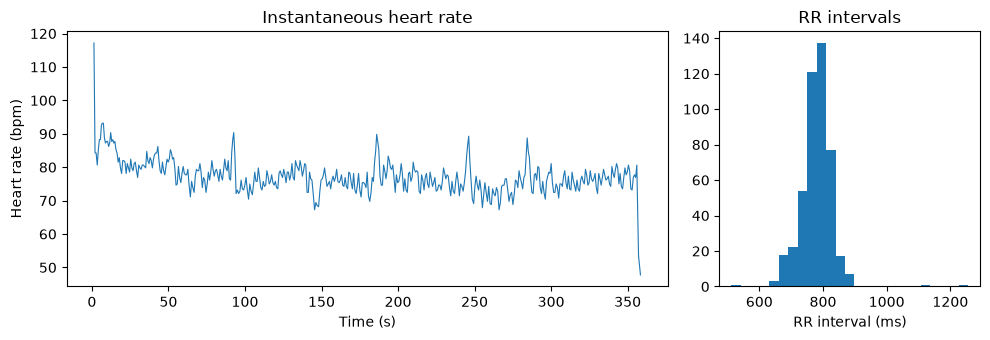

In [2]:
rr = np.diff(beats)                      # s
hr = 60 / rr                             # bpm
sdnn = rr.std(ddof=1) * 1000
rmssd = np.sqrt(np.mean(np.diff(rr) ** 2)) * 1000
print(f'RR: {rr.min() * 1000:.0f}-{rr.max() * 1000:.0f} ms, mean {rr.mean() * 1000:.0f} ms')
print(f'Mean heart rate {hr.mean():.0f} bpm   SDNN {sdnn:.0f} ms   RMSSD {rmssd:.0f} ms')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw=dict(width_ratios=[3, 1.3]))
axes[0].plot(beats[1:], hr, lw=.8)
axes[0].set(xlabel='Time (s)', ylabel='Heart rate (bpm)', title='Instantaneous heart rate')
axes[1].hist(rr * 1000, bins=25, color='tab:blue')
axes[1].set(xlabel='RR interval (ms)', title='RR intervals')
fig.tight_layout()

## Heartbeat-locked EEG

We cut EEG epochs from −0.2 s to +0.6 s around every heartbeat, use −0.2…−0.05 s as baseline, and drop epochs above 150 µV. Averaging across beats cancels everything that is not time-locked to the heart.

456 of 460 epochs kept


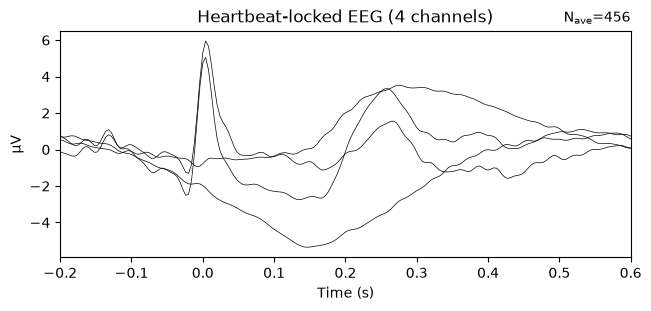

In [3]:
eeg = raw.copy().pick('eeg')
events, event_id = mne.events_from_annotations(eeg, event_id={'R_peak': 1})
epochs = mne.Epochs(eeg, events, event_id, tmin=-0.2, tmax=0.6, baseline=(-0.2, -0.05),
                    reject=dict(eeg=150e-6), preload=True)
print(f'{len(epochs)} of {len(events)} epochs kept')
evoked = epochs.average()
evoked.plot(spatial_colors=False, show=False, titles='Heartbeat-locked EEG');

### What you see

- **At 0 ms: a sharp peak.** This is the electrical field of the heart itself reaching the scalp electrodes, the *cardiac field artefact*. It is not brain activity, but it is a useful sanity check that heartbeat timing and EEG are aligned, and it can be removed if you only care about the brain.
- **Later, a slow component (roughly 0.25 s here).** The window about 200–600 ms after the beat is where researchers study *heartbeat-evoked potentials*, brain responses linked to how the brain tracks the body's signals. Such studies need many more beats, careful artefact handling and appropriate statistics.

Below, every single beat as a row of colour for one channel (in recording order), with the average underneath.

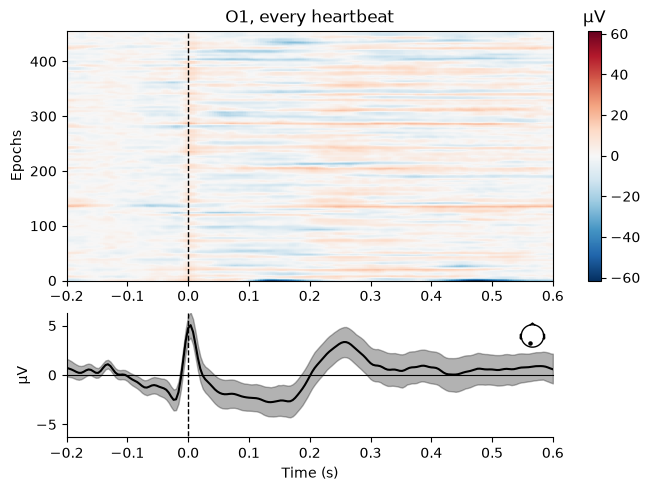

In [4]:
mne.viz.plot_epochs_image(epochs, picks=['O1'], sigma=2., show=False, title='O1, every heartbeat');

## Try it live

```python
from brainaccess import EEGManager
from brainaccess.utils import EEG

eeg = EEG(mode="roll")                  # keeps the most recent 10 s
with EEGManager() as mgr:
    eeg.setup(mgr, device_name="BA MINI 001")  # cap=... maps electrode index -> channel name
    eeg.start_acquisition()
    # ... wait a few seconds, then in your loop:
    raw = eeg.get_mne(tim=4)            # last 4 s as an mne.io.Raw
    eeg.stop_acquisition()
eeg.close()
```

A complete live script is in the kit: `python/live_band_power.py`.

Or let **BrainAccess Board** handle the headset and read its live data:

```python
import brainaccess_board as bb

db, ok = bb.db_connect()
raws = db.get_mne(duration=4)           # last 4 s of every connected device, as MNE Raw objects
```
